In [ ]:
#Importar paquetes de datos
import os
import sys
import glob
import numpy as np
import pandas as pd
from google.colab import drive

#Importar paquetes de audio
import librosa
import librosa.display
from scipy.io import wavfile
import scipy.io.wavfile
import sys

#Importar paquetes de trazado
import matplotlib.pyplot as plt
from matplotlib.pyplot import specgram
import matplotlib.pyplot as plt
import seaborn as sns

#Importar paquetes Keras y Tensorflow
import keras
from keras import regularizers
from keras.preprocessing import sequence
from keras.models import Sequential
from keras.layers import Dense, Embedding
from keras.layers import LSTM
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.utils import to_categorical
from keras.layers import Input, Flatten, Dropout, Activation
from keras.layers import Conv1D, MaxPooling1D, AveragePooling1D
from keras.models import Model
from keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix

In [ ]:
#Construir lista de archivos

#Montar Google Drive
drive.mount('/content/drive')

# Ruta del directorio a su conjunto de datos
dataset_path = '/content/drive/MyDrive/dataset/'
rawdata_list = os.listdir(dataset_path)

Mounted at /content/drive


In [ ]:
#Revisar lista de archivos
print(rawdata_list)

['Anger_F_A_izquierda.wav', 'Anger_C_A_gracias.wav', 'Anger_F_A_pronto.wav', 'Anger_C_B_ceguera.wav', 'Anger_C_A_pronto.wav', 'Anger_C_B_abuso.wav', 'Anger_F_A_abajo.wav', 'Anger_C_B_catastrofe.wav', 'Anger_C_B_explosion.wav', 'Anger_C_A_derecha.wav', 'Anger_C_B_ataque.wav', 'Anger_C_B_danino.wav', 'Anger_F_A_delante.wav', 'Anger_C_B_injusticia.wav', 'Anger_F_A_rapido.wav', 'Anger_C_B_delincuencia.wav', 'Anger_C_B_amenazado.wav', 'Anger_C_B_enojo.wav', 'Anger_C_A_no.wav', 'Anger_C_A_por_favor.wav', 'Anger_C_A_delante.wav', 'Anger_F_A_arriba.wav', 'Anger_C_B_alterado.wav', 'Anger_F_A_por_favor.wav', 'Anger_C_B_robo.wav', 'Anger_C_A_detras.wav', 'Anger_C_A_antes.wav', 'Anger_F_A_derecha.wav', 'Anger_C_B_explosivo.wav', 'Anger_F_A_no.wav', 'Anger_C_A_fuera.wav', 'Anger_F_A_antes.wav', 'Anger_F_B_abuso.wav', 'Anger_F_A_hola.wav', 'Anger_F_A_adios.wav', 'Anger_C_A_de_nada.wav', 'Anger_C_A_si.wav', 'Anger_C_B_estricto.wav', 'Anger_C_A_hola.wav', 'Anger_F_A_lento.wav', 'Anger_F_A_gracias.wav'

In [ ]:
#sample feature
#librosa.core.load(path, sr=22050, mono=True, offset=0.0, duration=None, dtype=<class 'numpy.float32'>, res_type='kaiser_best')
res_type_s = 'kaiser_best'
duration_s = None #Carga todo el archivo
sample_rate_s = 22050 #Ajustar
offset_s = 0.0

#Mfcc
#librosa.feature.mfcc(y=None, sr=22050, S=None, n_mfcc=20, dct_type=2, norm='ortho', lifter=0, **kwargs)
mfcc_sample_rate = 22050
n_mfcc = 40
axis_mfcc = 1

In [ ]:
#CREMA-D obtiene características emocionales
# Cree listas vacías para emociones y rutas de archivos
file_emotion = []
file_paths = []

# Iterar a través de todos los archivos en el directorio
for file_name in os.listdir(dataset_path):
  # Construya la ruta completa del archivo
  file_path_full = os.path.join(dataset_path, file_name)
  # Compruebe si el archivo es un archivo de audio (asumiendo formato WAV)
  if file_name.lower().endswith('.wav') and os.path.isfile(file_path_full):
    # Almacenar rutas de archivos
    file_paths.append(file_path_full)
    # almacenar emociones de archivos
    part = file_name.split('_')
    if part[0] == 'Sadness':
      file_emotion.append('sad')
    elif part[0] == 'Anger':
      file_emotion.append('angry')
    elif part[0] == 'Disgust':
      file_emotion.append('disgust')
    elif part[0] == 'Fear':
      file_emotion.append('fear')
    elif part[0] == 'Happiness':
      file_emotion.append('happy')
    elif part[0] == 'Neutral':
     file_emotion.append('neutral')
    else:
     file_emotion.append('Unknown')


In [ ]:
part

['Sadness', 'F', 'A', 'ayer.wav']

In [ ]:
#Check list
file_emotion

['angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',
 'angry',


In [ ]:
##Convertir lista en marco de datos
labels = pd.DataFrame(file_emotion)

In [ ]:
#comprobar la forma
labels.shape

(574, 1)

In [ ]:
#Cambiar el nombre del índice a "emoción"
labels = labels.rename({0: 'emotion'}, axis=1)

In [ ]:
labels.shape

(574, 1)

In [ ]:
#Numero de emociones
labels_total = pd.DataFrame(labels.groupby(['emotion']).size())
labels_total

,0
emotion,
angry,143
happy,144
neutral,143
sad,144


In [ ]:
#Número de archivos por emoción
labels_total = pd.DataFrame(labels.groupby(['emotion']).size())
labels_total

,0
emotion,
angry,143
happy,144
neutral,143
sad,144


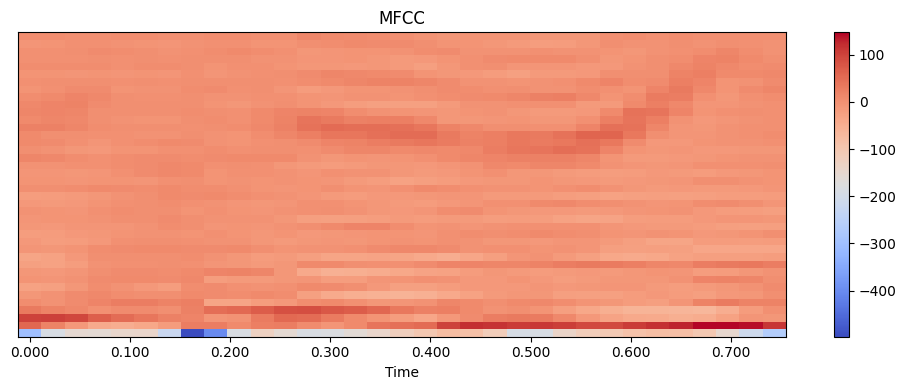

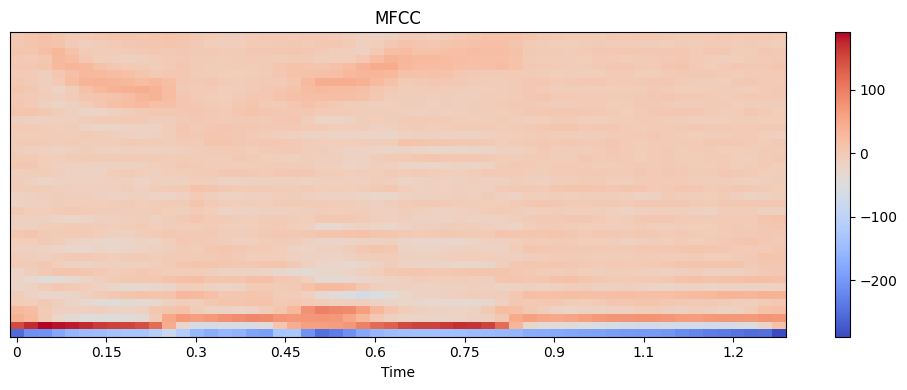

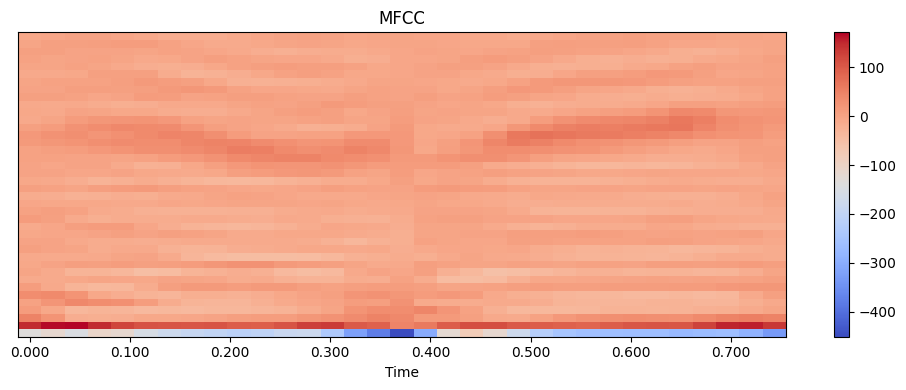

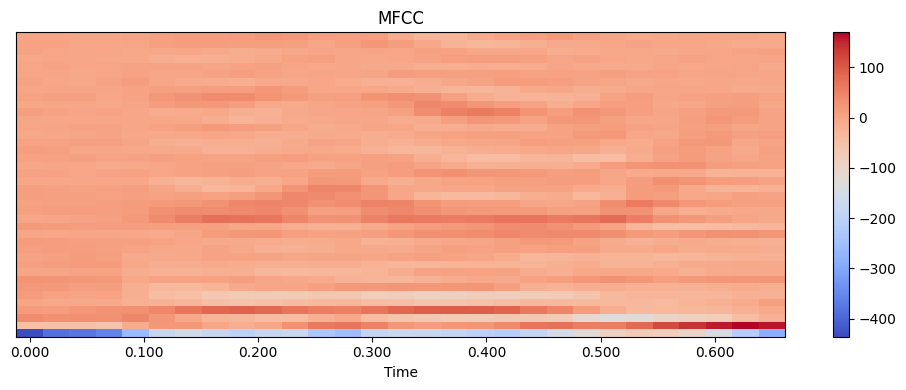

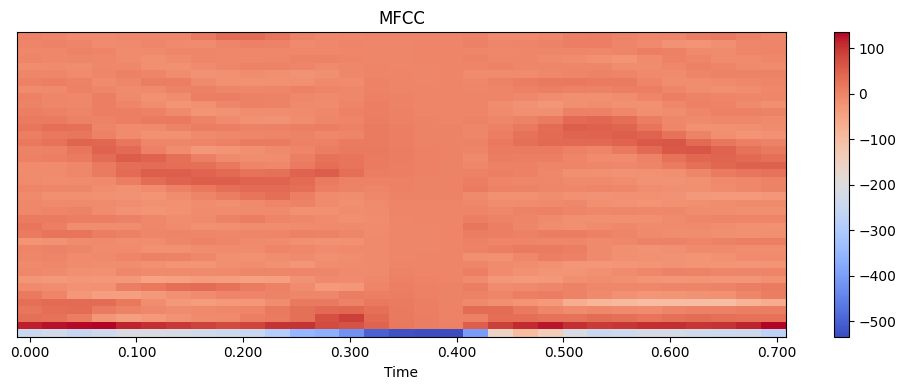

...

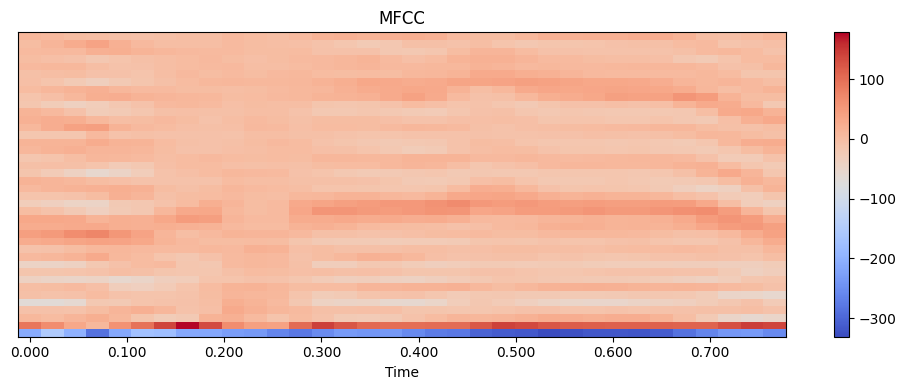

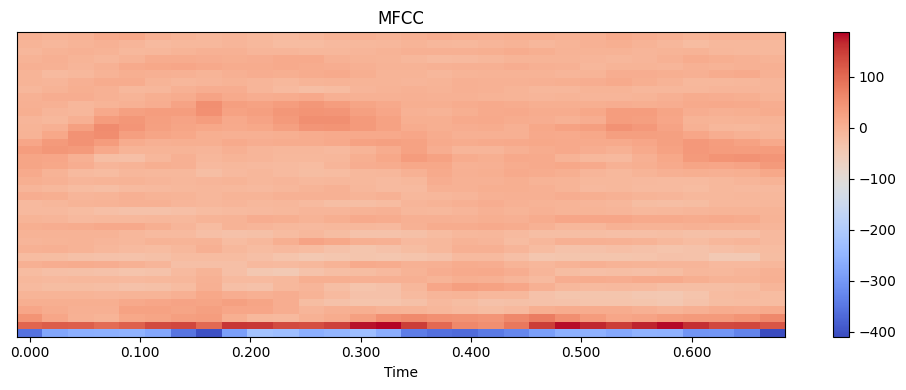

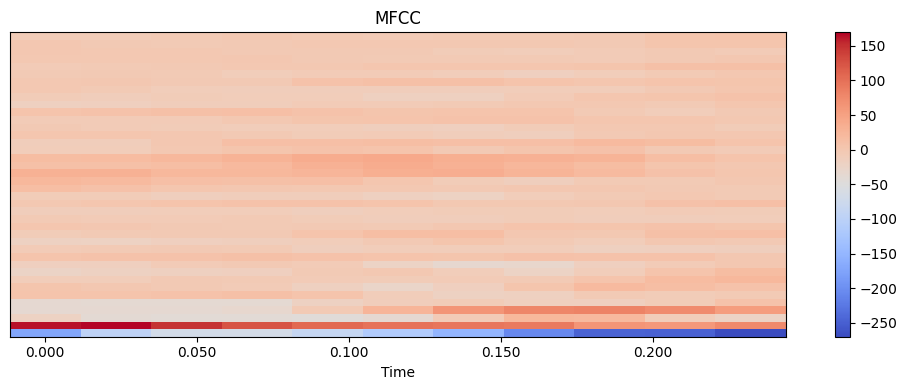

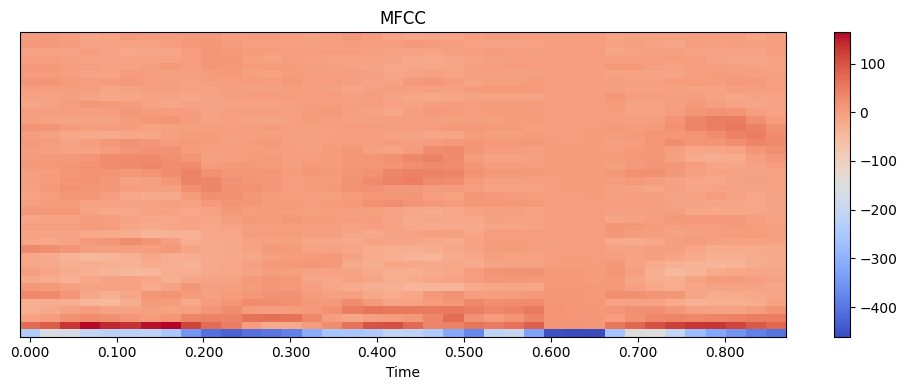

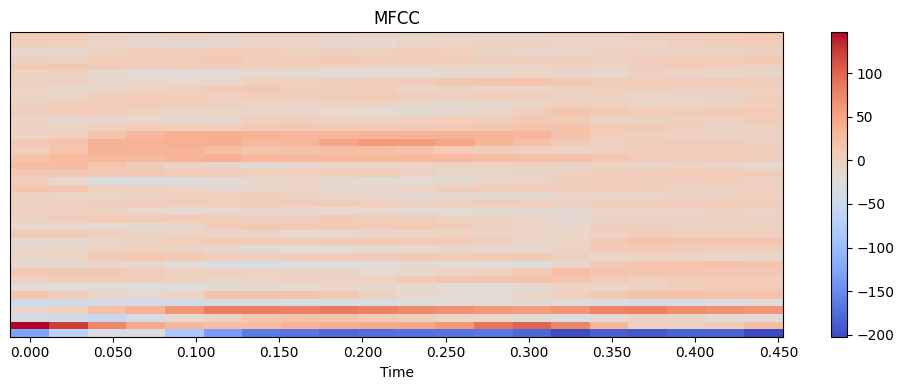

In [ ]:
#Obtiene funciones de audio con la biblioteca librosa
rawdata_crema = pd.DataFrame(columns=['feature'])
bookmark=0

for y in rawdata_list:
    #22050 kHz


    X, sample_rate = librosa.load(dataset_path+y,
                                  #res_type = res_type_s,
                                  duration = duration_s,
                                  sr = sample_rate_s,
                                  offset = offset_s)
    sample_rate = np.array(sample_rate)

    #Obtenga MFCC de cada archivo
    mfccs = librosa.feature.mfcc(   y=X,
                                    sr = mfcc_sample_rate,
                                    n_mfcc = n_mfcc)

    #Calcular la media de las MFCC
    #Revisar!!!!
    mfccs_mean = np.mean(    mfccs,
                             axis = axis_mfcc)
    feature = mfccs_mean

    #Agregar resultados de funciones de MFCC a la lista
    rawdata_crema.loc[bookmark] = [feature]
    bookmark=bookmark+1

    # Visualizar MFCC
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(mfccs, sr=sample_rate, x_axis='time')
    plt.colorbar()
    plt.title('MFCC')
    plt.tight_layout()
    plt.show()
    #Revisar mostrar los datos condesados...
    #Promediar por palabras, por emocion
    #Son diferentes las graficas en los 4 estados,

In [ ]:
#Resultados de datos de verdad
rawdata_crema.shape

(574, 1)

In [ ]:
#Verificar que no haya valores nulos
rawdata_crema.isnull().values.any()

False

In [ ]:
# Ver muestra de matriz de características
rawdata_crema

,feature
0,"[-168.99683, 58.961437, 13.426639, 9.94099, 3...."
1,"[-179.61462, 43.438164, 37.009705, 4.7476707, ..."
2,"[-220.3375, 113.404434, 17.486261, -15.481144,..."
3,"[-205.99835, 42.17536, -39.799194, 39.590046, ..."
4,"[-282.88425, 91.746635, 18.33391, 11.352091, -..."
...,...
569,"[-257.7291, 104.83106, -1.6955785, -3.6599555,..."
570,"[-295.46307, 133.94118, 30.244743, 5.5131164, ..."
571,"[-157.52412, 108.78108, -19.634796, 21.551569,..."
572,"[-292.3832, 76.396255, 25.444483, 16.03457, -1..."


In [ ]:
#Convertir matriz en marco de datos
rawdata_crema_final = pd.DataFrame(rawdata_crema['feature'].values.tolist())

In [ ]:
#Analizar nueva forma de marco de datos
rawdata_crema_final.shape

(574, 40)

In [ ]:
#Verificar muestra de datos
rawdata_crema_final.head()

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-168.996826,58.961437,13.426639,9.940990,3.444544,-14.862435,-8.255997,-4.277983,-12.408654,8.304171,...,-2.348031,5.412806,1.817964,5.885489,-0.624983,-1.384839,0.954924,0.423995,-2.558387,1.600136
1,-179.614624,43.438164,37.009705,4.747671,-8.031432,2.698426,-9.993720,-0.564772,-5.075295,-3.582418,...,0.138897,4.733703,5.010789,9.689962,6.505931,10.791382,4.240623,5.977687,2.381706,3.315002
2,-220.337494,113.404434,17.486261,-15.481144,-9.588907,-9.203531,4.489330,-10.862262,-26.241055,5.320630,...,-4.957756,-1.417764,-0.138917,0.426109,-3.595228,-4.130097,-5.364705,-5.365875,-1.337963,-4.717998
3,-205.998352,42.175362,-39.799194,39.590046,-30.410831,-47.204109,-2.780634,5.595084,-10.584180,-12.268703,...,6.848861,8.579099,-2.338765,-2.359696,3.527367,-3.206256,-0.774517,-2.440667,-0.556599,2.623596
4,-282.884247,91.746635,18.333910,11.352091,-24.849966,-6.315955,0.958881,-23.140306,-6.208920,-15.112589,...,-6.091309,-1.809404,-1.012315,-1.291862,-5.527568,-4.856161,-4.988824,-2.347139,-2.730465,3.983693


In [ ]:
#Unir etiquetas con características
newdf_crema = pd.concat([rawdata_crema_final,labels], axis=1)

In [ ]:
#Cambiar el nombre del marco de datos
newdf_crema = newdf_crema.rename(index=str, columns={"0": "label"})

In [ ]:
#Analizar la forma del marco de datos
newdf_crema.shape

(574, 41)

In [ ]:
#Analizar muestra de marco de datos
newdf_crema.head()

,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,emotion
0,-168.996826,58.961437,13.426639,9.940990,3.444544,-14.862435,-8.255997,-4.277983,-12.408654,8.304171,...,5.412806,1.817964,5.885489,-0.624983,-1.384839,0.954924,0.423995,-2.558387,1.600136,angry
1,-179.614624,43.438164,37.009705,4.747671,-8.031432,2.698426,-9.993720,-0.564772,-5.075295,-3.582418,...,4.733703,5.010789,9.689962,6.505931,10.791382,4.240623,5.977687,2.381706,3.315002,angry
2,-220.337494,113.404434,17.486261,-15.481144,-9.588907,-9.203531,4.489330,-10.862262,-26.241055,5.320630,...,-1.417764,-0.138917,0.426109,-3.595228,-4.130097,-5.364705,-5.365875,-1.337963,-4.717998,angry
3,-205.998352,42.175362,-39.799194,39.590046,-30.410831,-47.204109,-2.780634,5.595084,-10.584180,-12.268703,...,8.579099,-2.338765,-2.359696,3.527367,-3.206256,-0.774517,-2.440667,-0.556599,2.623596,angry
4,-282.884247,91.746635,18.333910,11.352091,-24.849966,-6.315955,0.958881,-23.140306,-6.208920,-15.112589,...,-1.809404,-1.012315,-1.291862,-5.527568,-4.856161,-4.988824,-2.347139,-2.730465,3.983693,angry


In [ ]:
#Datafram drop Nan values
newdf_crema.dropna(inplace=True)

In [ ]:
from sklearn.utils import shuffle

#Shuffle dataframe
newdf_crema = shuffle(newdf_crema)
newdf_crema.head(10)

,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,emotion
29,-173.738235,106.006554,-12.222205,-40.047928,-19.230818,-27.858450,8.910881,-6.684463,-34.096577,17.881752,...,2.700631,11.939040,4.717615,-1.751911,-2.462464,-4.110601,1.428889,-5.003203,-4.887292,angry
24,-203.662003,118.149185,-19.685564,3.010932,-50.063457,-26.965126,-10.875568,-15.919863,-0.156379,-17.665697,...,-1.616533,-1.944934,-0.399846,-5.086341,-1.521769,-3.657213,-3.449727,-2.365120,-1.068639,angry
6,-188.814133,123.751549,1.008530,-28.900885,-22.301502,-19.117863,-6.802219,10.467212,-33.046810,11.848016,...,1.495315,5.623775,10.962362,3.190844,8.991767,-1.249357,0.352111,-5.854616,-0.866962,angry
210,-221.634399,100.173241,15.157127,24.337357,-4.879087,12.183895,-8.310880,-5.192943,-8.278176,-7.793532,...,-1.798203,-5.070317,1.257376,-4.449690,-4.241426,-6.251485,-2.914437,-6.966264,-1.981855,neutral
477,-192.075821,88.790428,-15.988792,25.075686,1.956519,4.251172,-5.982741,-5.993413,2.014457,5.553272,...,2.195280,-1.775004,-0.808666,-7.445315,2.419674,-0.531628,-2.943329,-4.879907,2.764589,sad
71,-188.990921,57.981342,-2.319438,50.730301,-9.323562,-21.137842,-10.055053,-5.143571,-24.368315,-0.116960,...,7.994162,1.611957,0.227485,-0.635359,-4.457859,-1.932736,0.430965,-2.798890,-2.394228,angry
472,-189.834305,76.133293,-32.537537,28.013079,-2.902406,-8.488470,-10.163155,-9.032770,4.139544,-3.642861,...,3.549506,0.718865,-0.012418,-5.469204,-1.370619,-2.970527,-0.164238,-3.251969,-3.738277,sad
204,-223.148361,106.085869,-1.782816,36.273388,-36.382687,-17.839304,-15.556315,-17.921158,0.892547,-13.287192,...,-3.222546,-0.812275,-1.293696,-3.811764,-2.208967,-0.920500,-2.879282,-2.521298,-0.729735,neutral
82,-148.683990,54.549416,18.175474,24.799185,2.814696,-17.159174,-15.206874,1.159032,-20.803568,3.892679,...,3.123207,2.324608,4.767659,1.151765,5.627877,1.791040,2.323200,-2.496469,0.592063,angry
4,-282.884247,91.746635,18.333910,11.352091,-24.849966,-6.315955,0.958881,-23.140306,-6.208920,-15.112589,...,-1.809404,-1.012315,-1.291862,-5.527568,-4.856161,-4.988824,-2.347139,-2.730465,3.983693,angry


In [ ]:
#Verificar que no haya valores nulos
newdf_crema.isnull().values.any()

False

In [ ]:
# Verificar muestra de marco de datos
newdf_crema.head(5)

,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,emotion
29,-173.738235,106.006554,-12.222205,-40.047928,-19.230818,-27.858450,8.910881,-6.684463,-34.096577,17.881752,...,2.700631,11.939040,4.717615,-1.751911,-2.462464,-4.110601,1.428889,-5.003203,-4.887292,angry
24,-203.662003,118.149185,-19.685564,3.010932,-50.063457,-26.965126,-10.875568,-15.919863,-0.156379,-17.665697,...,-1.616533,-1.944934,-0.399846,-5.086341,-1.521769,-3.657213,-3.449727,-2.365120,-1.068639,angry
6,-188.814133,123.751549,1.008530,-28.900885,-22.301502,-19.117863,-6.802219,10.467212,-33.046810,11.848016,...,1.495315,5.623775,10.962362,3.190844,8.991767,-1.249357,0.352111,-5.854616,-0.866962,angry
210,-221.634399,100.173241,15.157127,24.337357,-4.879087,12.183895,-8.310880,-5.192943,-8.278176,-7.793532,...,-1.798203,-5.070317,1.257376,-4.449690,-4.241426,-6.251485,-2.914437,-6.966264,-1.981855,neutral
477,-192.075821,88.790428,-15.988792,25.075686,1.956519,4.251172,-5.982741,-5.993413,2.014457,5.553272,...,2.195280,-1.775004,-0.808666,-7.445315,2.419674,-0.531628,-2.943329,-4.879907,2.764589,sad


In [ ]:
#Analizar la forma del marco de datos
newdf_crema.shape

(574, 41)

In [ ]:
# Ver numero de emociones
newdf_crema[newdf_crema.columns[-1]].nunique()

4

Dividiendo los datos en test y train

In [ ]:
#Dividir funciones de objetivos
X = newdf_crema.iloc[:,:-1]

#Objetivos divididos
y = newdf_crema.iloc[:,-1]

In [ ]:
#Obtenga una muestra de funciones
X

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
29,-173.738235,106.006554,-12.222205,-40.047928,-19.230818,-27.858450,8.910881,-6.684463,-34.096577,17.881752,...,3.125440,2.700631,11.939040,4.717615,-1.751911,-2.462464,-4.110601,1.428889,-5.003203,-4.887292
24,-203.662003,118.149185,-19.685564,3.010932,-50.063457,-26.965126,-10.875568,-15.919863,-0.156379,-17.665697,...,-1.485037,-1.616533,-1.944934,-0.399846,-5.086341,-1.521769,-3.657213,-3.449727,-2.365120,-1.068639
6,-188.814133,123.751549,1.008530,-28.900885,-22.301502,-19.117863,-6.802219,10.467212,-33.046810,11.848016,...,2.681127,1.495315,5.623775,10.962362,3.190844,8.991767,-1.249357,0.352111,-5.854616,-0.866962
210,-221.634399,100.173241,15.157127,24.337357,-4.879087,12.183895,-8.310880,-5.192943,-8.278176,-7.793532,...,-5.152172,-1.798203,-5.070317,1.257376,-4.449690,-4.241426,-6.251485,-2.914437,-6.966264,-1.981855
477,-192.075821,88.790428,-15.988792,25.075686,1.956519,4.251172,-5.982741,-5.993413,2.014457,5.553272,...,-0.222388,2.195280,-1.775004,-0.808666,-7.445315,2.419674,-0.531628,-2.943329,-4.879907,2.764589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,-226.160645,109.203239,7.725134,26.561653,-12.460124,0.362480,-25.393631,-10.521192,-17.958782,-11.680926,...,7.771824,10.282623,7.371305,10.339141,11.666902,5.074680,-1.067446,-2.111255,-5.674157,3.001787
481,-223.052734,131.865265,15.908432,14.735631,-25.989981,-13.899035,-10.201508,-7.757534,-18.924040,-8.465517,...,-3.432294,-6.395265,0.174137,14.672900,20.718632,31.828226,23.871046,14.709574,3.574347,-2.106422
420,-176.735229,-12.020350,-31.471270,41.065670,-14.755636,-46.505978,-0.934749,-23.326897,-1.177760,-24.012375,...,8.487980,6.245238,5.595630,-1.053885,2.797066,4.231328,-3.767958,3.724798,-1.598767,-4.528807
419,-179.176102,25.556828,11.631723,3.898240,-29.009331,-9.523991,-4.411203,-6.465022,-14.582396,-11.258888,...,-3.474030,1.624908,0.180794,1.865630,-3.262033,0.511082,-2.225427,3.342864,-0.807523,3.568567


In [ ]:
from sklearn.model_selection import train_test_split

#Dividir conjunto de datos de prueba y train
#test_size=0.2
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=1)

# Consulta los datos
print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')

X_train shape: (459, 40)
y_train shape: (459,)
X_test shape: (115, 40)
y_test shape: (115,)


In [ ]:
#Verifique valores únicos para y_test
y_test.unique()

array(['sad', 'angry', 'neutral', 'happy'], dtype=object)

In [ ]:
#Verifique valores únicos para y_train
y_train.unique()

array(['sad', 'angry', 'neutral', 'happy'], dtype=object)

In [ ]:
#Codificación de etiquetas
from keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
#Revisar

lb = LabelEncoder()

#Codifique etiquetas de emociones en números
y_train_lb = to_categorical(lb.fit_transform(y_train))
y_test_lb = to_categorical(lb.fit_transform(y_test))

# Consulta los datos
print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train_lb.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test_lb.shape}')

X_train shape: (459, 40)
y_train shape: (459, 4)
X_test shape: (115, 40)
y_test shape: (115, 4)


In [ ]:
#Comprobar codificación
np.unique(y_train_lb, axis=0)

array([[0., 0., 0., 1.],
       [0., 0., 1., 0.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.]], dtype=float32)

In [ ]:
#rango de valores x
#Verificar
print(f'X range: {X_train.min()}-{X_train.max()}')
# y valores únicos
print(f'y values: {np.unique(y_train_lb)}')
num_classes = len(np.unique(y_train_lb))
print(f'Number of classes: {num_classes}')

X range: 0    -375.097900
1     -40.027573
2    -100.998772
3     -33.652744
4     -83.112274
5     -54.903511
6     -45.789574
7     -42.608162
8     -45.517899
9     -31.652315
10    -31.147991
11    -26.826038
12    -27.253927
13    -19.622828
14    -29.477379
15    -26.102287
16    -28.638422
17    -19.030684
18    -26.081869
19    -18.290642
20    -17.774673
21    -17.498001
22    -21.749802
23    -18.013472
24    -17.040386
25    -16.018265
26    -15.349165
27    -19.104565
28    -10.887505
29    -12.110960
30    -13.717500
31     -8.992466
32    -10.472763
33    -10.341677
34    -13.101161
35     -7.839376
36    -10.596251
37    -10.257807
38    -11.288009
39    -12.741854
dtype: float32-0     -74.155487
1     180.046982
2      58.651917
3      69.459351
4      16.457695
5      26.544062
6      12.468454
7      15.663810
8      21.542147
9      23.571262
10     34.758747
11     36.893040
12     18.098610
13     44.308159
14     33.050617
15     40.539497
16     32.582100
17     

Cree una lista de etiquetas para crear una matriz de confusión tras el modelo

In [ ]:
#Verifique las etiquetas de codificación
lb.classes_

array(['angry', 'happy', 'neutral', 'sad'], dtype=object)

In [ ]:
#Cree nuevas listas de etiquetas de codificación
y_labels_encoded = {}
for i, label in enumerate(lb.classes_):
    y_labels_encoded[i] = label

y_labels_encoded

{0: 'angry', 1: 'happy', 2: 'neutral', 3: 'sad'}

Escalar datos para análisis

In [ ]:
from sklearn.preprocessing import StandardScaler
#Normalizar los datos
#Revisar
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scalled = scaler.transform(X_train)
X_test_scalled = scaler.transform(X_test)

Modelo de construcción: red neuronal convolucional Cambiar dimensiones para el modelo CNN

In [ ]:
#Agregar dimensión para CNN
x_traincnn = np.expand_dims(X_train_scalled, axis=2)
x_testcnn = np.expand_dims(X_test_scalled, axis=2)

#Verificar formas de marcos de datos
print(x_traincnn.shape)
print(x_testcnn.shape)

(459, 40, 1)
(115, 40, 1)


In [ ]:
#Importar paquetes para CNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Conv1D
from tensorflow.keras.layers import Dense, Dropout, Embedding, LSTM, BatchNormalization, Flatten, MaxPooling2D

In [ ]:
#Construir CNN secuencial
CNN_model = Sequential()

#Construir la primera capa
CNN_model.add(Conv1D(32, 5,padding='same',
                 input_shape=(40, 1), activation='relu'))

#Construir segunda capa
CNN_model.add(Conv1D(128, 5,padding='same',activation='relu'))

#Construir tercera capa
CNN_model.add(Conv1D(64, 5,padding='same',activation='relu'))

#Construir capa
CNN_model.add(Conv1D(32, 5,padding='same',activation='relu'))

#Add dropout
#CNN_model.add(Dropout(0.1))

#Flatten
CNN_model.add(Flatten())

CNN_model.add(Dense(128, activation ='relu'))
CNN_model.add(Dropout(0.1))
CNN_model.add(Dense(64, activation ='relu'))
CNN_model.add(Dense(4, activation='softmax'))

In [ ]:
#Mire el resumen del modelo de CNN
CNN_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 40, 32)            192       
                                                                 
 conv1d_1 (Conv1D)           (None, 40, 128)           20608     
                                                                 
 conv1d_2 (Conv1D)           (None, 40, 64)            41024     
                                                                 
 conv1d_3 (Conv1D)           (None, 40, 32)            10272     
                                                                 
 flatten (Flatten)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 128)               163968    
                                                                 
 dropout (Dropout)           (None, 128)               0

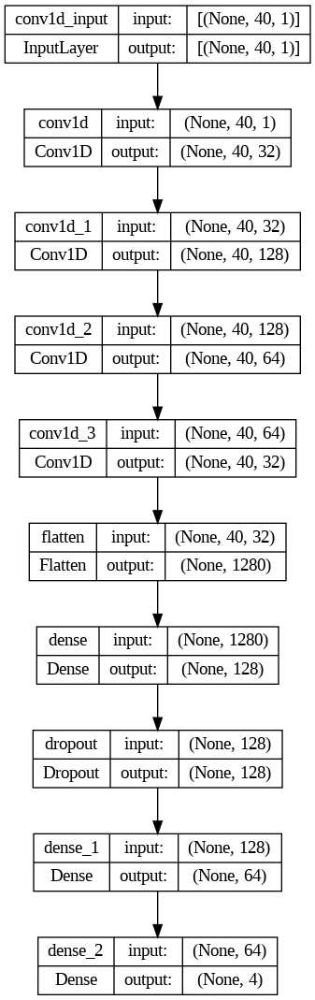

In [ ]:
from keras.utils import plot_model

# Guarde una imagen de la arquitectura del modelo en un archivo.
plot_model(CNN_model, to_file='Feed Forward NN.png', show_shapes=True, show_layer_names=True)

In [ ]:
# Compile el modelo con la función de pérdida, el optimizador y la métrica deseados para optimizar
CNN_model.compile(loss = 'categorical_crossentropy',
                  optimizer = 'Adam',
                  metrics = ['accuracy'])

In [ ]:
from keras.callbacks import ModelCheckpoint

checkpointer = ModelCheckpoint(filepath='saved_models/weights.best.basic_cnn.hdf5',
                               verbose=1, save_best_only=True)

#Model fit

cnn_results = CNN_model.fit(x_traincnn, y_train_lb,
              batch_size = 16,
              epochs = 50,
              verbose = 1,
              validation_data = (x_testcnn, y_test_lb))

Epoch 1/50
29/29 [==============================] - 4s 24ms/step - loss: 1.1742 - accuracy: 0.5011 - val_loss: 0.9249 - val_accuracy: 0.6609
Epoch 2/50
29/29 [==============================] - 0s 16ms/step - loss: 0.7823 - accuracy: 0.6797 - val_loss: 0.7126 - val_accuracy: 0.7565
Epoch 3/50
29/29 [==============================] - 0s 14ms/step - loss: 0.5154 - accuracy: 0.7974 - val_loss: 0.5093 - val_accuracy: 0.8261
Epoch 4/50
29/29 [==============================] - 0s 15ms/step - loss: 0.3062 - accuracy: 0.8932 - val_loss: 0.3940 - val_accuracy: 0.8957
Epoch 5/50
29/29 [==============================] - 0s 15ms/step - loss: 0.1815 - accuracy: 0.9325 - val_loss: 0.4860 - val_accuracy: 0.8174
Epoch 6/50
29/29 [==============================] - 0s 15ms/step - loss: 0.1802 - accuracy: 0.9303 - val_loss: 0.5746 - val_accuracy: 0.7565
Epoch 7/50
29/29 [==============================] - 0s 15ms/step - loss: 0.1329 - accuracy: 0.9564 - val_loss: 0.4681 - val_accuracy: 0.8696
Epoch 8/50
29

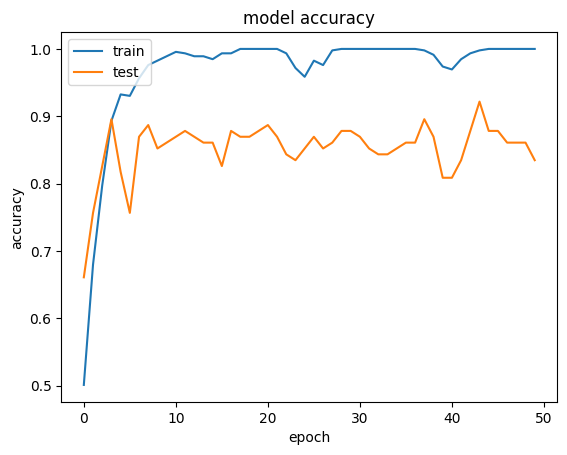

In [ ]:
#Trazar la precisión del modelo sobre ephocs
plt.plot(cnn_results.history['accuracy'])
plt.plot(cnn_results.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

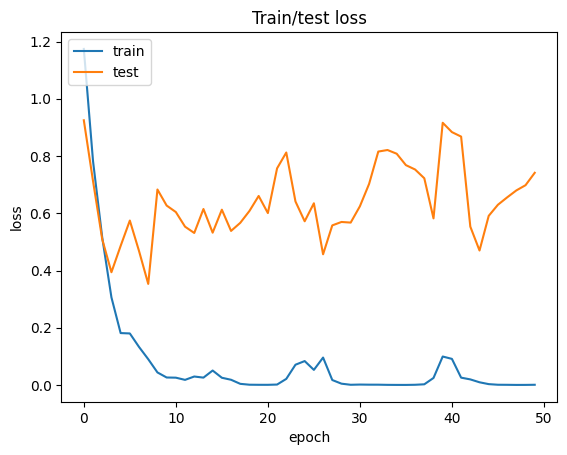

In [ ]:
#Trazar la precisión del modelo sobre ephocs
plt.plot(cnn_results.history['loss'])
plt.plot(cnn_results.history['val_loss'])
plt.title('Train/test loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
# Calcular la precisión previa al entrenamiento
score = CNN_model.evaluate(x_testcnn, y_test_lb, verbose=1)
accuracy = 100*score[1]

print("Pre-training accuracy: %.4f%%" % accuracy)

4/4 [==============================] - 0s 12ms/step - loss: 0.7414 - accuracy: 0.8348
Pre-training accuracy: 83.4783%


In [ ]:
# Evaluación del modelo en el conjunto de entrenamiento y prueba.
score = CNN_model.evaluate(x_traincnn, y_train_lb, verbose=0)
print("Training Accuracy: ", score[1])

score = CNN_model.evaluate(x_testcnn, y_test_lb, verbose=0)
print("Testing Accuracy: ", score[1])

Training Accuracy:  1.0
Testing Accuracy:  0.834782600402832


Agregar matriz de confusión

In [ ]:
#Obtener predicciones del modelo
y_test_predictions_inter = CNN_model.predict(x_testcnn)
y_test_predictions=np.argmax(y_test_predictions_inter,axis=1)
y_test_predictions

4/4 [==============================] - 0s 9ms/step


array([3, 0, 1, 0, 0, 0, 3, 2, 1, 1, 3, 1, 0, 3, 0, 0, 3, 2, 3, 3, 1, 0,
       0, 3, 1, 0, 3, 0, 0, 3, 1, 1, 1, 2, 2, 1, 0, 1, 3, 0, 2, 1, 0, 3,
       2, 2, 2, 2, 3, 1, 3, 3, 3, 1, 1, 3, 3, 3, 0, 0, 0, 2, 0, 0, 1, 0,
       1, 0, 0, 2, 0, 2, 3, 0, 0, 1, 3, 1, 2, 1, 0, 1, 0, 2, 0, 2, 3, 1,
       0, 3, 1, 2, 2, 2, 0, 2, 1, 2, 1, 1, 3, 2, 1, 1, 1, 3, 3, 0, 1, 2,
       0, 3, 2, 1, 3])

In [ ]:
y_test

497        sad
17       angry
371    neutral
202      happy
5        angry
        ...   
111      angry
446        sad
299    neutral
154      happy
459        sad
Name: emotion, Length: 115, dtype: object

In [ ]:
#Obtener etiquetas para emociones
y_labels_encoded

{0: 'angry', 1: 'happy', 2: 'neutral', 3: 'sad'}

In [ ]:
# Cambiar predicciones a emociones para poder comparar.
y_test_predictions_labels =[]

#Revise cada predicción y agréguela a una nueva lista
for e in range(len(y_test_predictions)):
    y_test_predictions_labels.append(y_labels_encoded[y_test_predictions[e]])

#Construya una serie de predicciones
y_test_predictions_labels = np.array(y_test_predictions_labels)
y_test_predictions_labels

array(['sad', 'angry', 'happy', 'angry', 'angry', 'angry', 'sad',
       'neutral', 'happy', 'happy', 'sad', 'happy', 'angry', 'sad',
       'angry', 'angry', 'sad', 'neutral', 'sad', 'sad', 'happy', 'angry',
       'angry', 'sad', 'happy', 'angry', 'sad', 'angry', 'angry', 'sad',
       'happy', 'happy', 'happy', 'neutral', 'neutral', 'happy', 'angry',
       'happy', 'sad', 'angry', 'neutral', 'happy', 'angry', 'sad',
       'neutral', 'neutral', 'neutral', 'neutral', 'sad', 'happy', 'sad',
       'sad', 'sad', 'happy', 'happy', 'sad', 'sad', 'sad', 'angry',
       'angry', 'angry', 'neutral', 'angry', 'angry', 'happy', 'angry',
       'happy', 'angry', 'angry', 'neutral', 'angry', 'neutral', 'sad',
       'angry', 'angry', 'happy', 'sad', 'happy', 'neutral', 'happy',
       'angry', 'happy', 'angry', 'neutral', 'angry', 'neutral', 'sad',
       'happy', 'angry', 'sad', 'happy', 'neutral', 'neutral', 'neutral',
       'angry', 'neutral', 'happy', 'neutral', 'happy', 'happy', 'sad',
 

In [ ]:
from sklearn.metrics import confusion_matrix

#Cree una matriz de confusión y vea los resultados
confusion_matrix = confusion_matrix(y_test, y_test_predictions_labels)
confusion_matrix

array([[26,  2,  1,  0],
       [ 7, 24,  3,  0],
       [ 0,  5, 18,  0],
       [ 0,  0,  1, 28]])

In [ ]:
#Ver forma de matriz de confusión
confusion_matrix.shape

(4, 4)

In [ ]:
#Agregar etiquetas a la matriz de confusión
confusion_matrix = pd.DataFrame(confusion_matrix, columns=list(y_labels_encoded.values()), index=list(y_labels_encoded.values()))

print("Las filas representan los valores verdaderos u observaciones.")
print("Las columnas representan las predicciones del modelo.")

#Imprimir resultados de la matriz de confusión
confusion_matrix

Las filas representan los valores verdaderos u observaciones.
Las columnas representan las predicciones del modelo.


,angry,happy,neutral,sad
angry,26,2,1,0
happy,7,24,3,0
neutral,0,5,18,0
sad,0,0,1,28


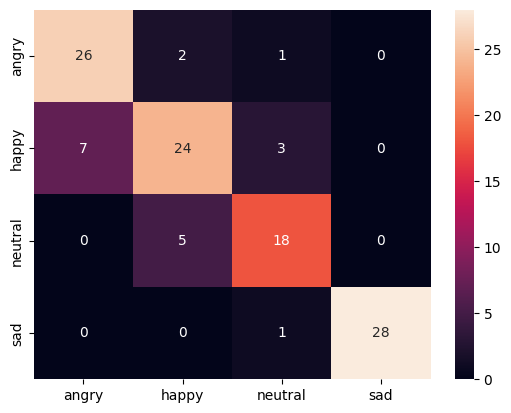

In [ ]:
#Trazar matriz de confusión con resultados
ax = sns.heatmap(confusion_matrix, annot=True)

Guardar Modelo CNN

In [ ]:
from keras.models import model_from_json
#Serializar el modelo a json
json_model = CNN_model.to_json()
#Guarde la arquitectura del modelo en un archivo JSON
with open('capstone_project_emotion_detection_final_version4.json', 'w') as json_file:
    json_file.write(json_model)
#Guardando los pesos del modelo
CNN_model.save_weights('capstone_project_emotion_detection_final_version4.h5')
#Pérdida y precisión del modelo.
print("Modelo guardado en el disco")

Modelo guardado en el disco


In [ ]:
# cargar json y crear modelo
json_file = open('capstone_project_emotion_detection_final_version4.json', 'r')
loaded_model_json = json_file.read()
json_file.close()
loaded_model = model_from_json(loaded_model_json)
# load weights into new model
loaded_model.load_weights("capstone_project_emotion_detection_final_version4.h5")
print("Modelo cargado desde el disco")

Modelo cargado desde el disco


In [ ]:
# cargar json y crear modelo
json_file = open('capstone_project_emotion_detection_final_version4.json', 'r')
loaded_model_json = json_file.read()
json_file.close()
loaded_model = model_from_json(loaded_model_json)
# load weights into new model
loaded_model.load_weights("capstone_project_emotion_detection_final_version4.h5")
print("Modelo cargado desde el disco")

Modelo cargado desde el disco


In [ ]:
from keras.initializers import glorot_uniform
#Leyendo el modelo del archivo JSON
with open('capstone_project_emotion_detection_final_version4.json', 'r') as json_file:
    json_savedModel= json_file.read()
#cargar la arquitectura del modelo
model_load = keras.models.model_from_json(json_savedModel)
model_load.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 40, 32)            192       
                                                                 
 conv1d_1 (Conv1D)           (None, 40, 128)           20608     
                                                                 
 conv1d_2 (Conv1D)           (None, 40, 64)            41024     
                                                                 
 conv1d_3 (Conv1D)           (None, 40, 32)            10272     
                                                                 
 flatten (Flatten)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 128)               163968    
                                                                 
 dropout (Dropout)           (None, 128)               0

In [ ]:
from keras.models import model_from_json

# Asumiendo que tienes un modelo CNN_model previamente entrenado
# Serializar el modelo a JSON
json_model = CNN_model.to_json()

# Guardar la arquitectura del modelo en un archivo JSON
json_file_path = 'capstone_project_emotion_detection_final_version5.json'
weights_file_path = 'capstone_project_emotion_detection_final_version5.h5'

with open(json_file_path, 'w') as json_file:
    json_file.write(json_model)

# Guardar los pesos del modelo
CNN_model.save_weights(weights_file_path)
print("Modelo guardado en el disco")

# Cargar el modelo desde el archivo JSON y los pesos
try:
    with open(json_file_path, 'r') as json_file:
        loaded_model_json = json_file.read()

    loaded_model = model_from_json(loaded_model_json)
    loaded_model.load_weights(weights_file_path)
    print("Modelo cargado desde el disco")
except FileNotFoundError as e:
    print(f"Error: {e}. Asegúrate de que los archivos {json_file_path} y {weights_file_path} existan en el directorio actual.")
except Exception as e:
    print(f"Se produjo un error al cargar el modelo: {e}")


Modelo guardado en el disco
Modelo cargado desde el disco
